# Transversal $T$ on the [[15,1,3]] code, step by step

> **In short.**
> * **The program.** Encode one qubit into the [[15,1,3]] code. Put a $T$ on every one of the 15 qubits. Then measure the four $X$ checks.
> * **The question.** Is the layer of $T$ gates a logical gate? Which one? Do the checks still work after it? How many faults does it take to break it?
> * **The answer.** It is the logical $T^\dagger$. It keeps the code. All four checks still read 0. It takes 3 $Z$ faults to change the stored qubit unseen.
> * **The broken version.** $T$ on 7 qubits only. It leaves the code. The program still gives $T^\dagger$ at the end, but 3 of the 4 checks are lost.
> * **The matrix test.** Section 2 shows the matrix $M$ and its three counts. The tool checks the same counts, by adding the $T$ gadgets up.
> * **Library calls only.** The interactive window is [interactive_triorthogonal_levels.py](interactive_triorthogonal_levels.py).

In [1]:
%matplotlib inline
from itertools import combinations
import pyzx as zx
from IPython.display import display
from pyzx.circuit import Circuit
from zxqec.qprogram import QProgram
from zxqec.qprogram.compare import compare_programs
from zxqec.qprogram.distance import circuit_distance, z_distance_through_t
from zxqec.gpf import phase_polynomial, reduce_gpf
from zxqec.spacetime import draw_program, view_levels

## 1. The program

* **Qubits.** Data qubits 0–14. The stored qubit comes in on qubit 14. Helpers 15–18 measure the checks.
* **The code.** Qubit $j$ stands for the number $j+1$ in binary. Check $b$ is an $X$ on the 8 qubits whose number has binary digit $b$ set. So there are 4 checks.
* **Three stages.** The encoder. A layer of $T$ gates. A round of the 4 $X$ checks, measured into `c[0]` to `c[3]`.
* **Two versions.** $T$ on all 15 qubits. $T$ on qubits 0–6 only.
* **Two references.** "$T^\dagger$ on the input, then encode", and the same with $T$. We compare against them in section 4.

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


[[15, 1, 3]] CSS code on qubits 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14
    stabilizer +XXIXIIXXIIXIXXI
    stabilizer +XXIXIIXIXXIXIIX
    stabilizer +XXIIXXIXIIXXIIX
    stabilizer +XIXXIXIXIXIIXIX
    stabilizer +ZZIZIIZIIIIIIII
    stabilizer +ZZIIZZIIIIIIIII
    stabilizer +ZZIIIIIZIIZIIII
    stabilizer +ZZIIIIIIZZIIIII
    stabilizer +ZZIIIIIIIIIZIIZ
    stabilizer +ZZIIIIIIIIIIZZI
    stabilizer +ZIZZIZIIIIIIIII
    stabilizer +ZIZIIIIZIZIIIII
    stabilizer +ZIZIIIIIIIIZIZI
    stabilizer +ZIIZIIIZIIIIZII
    logical X XXXXXXXIIIIIIII   logical Z ZZZIIIIIIIIIIII


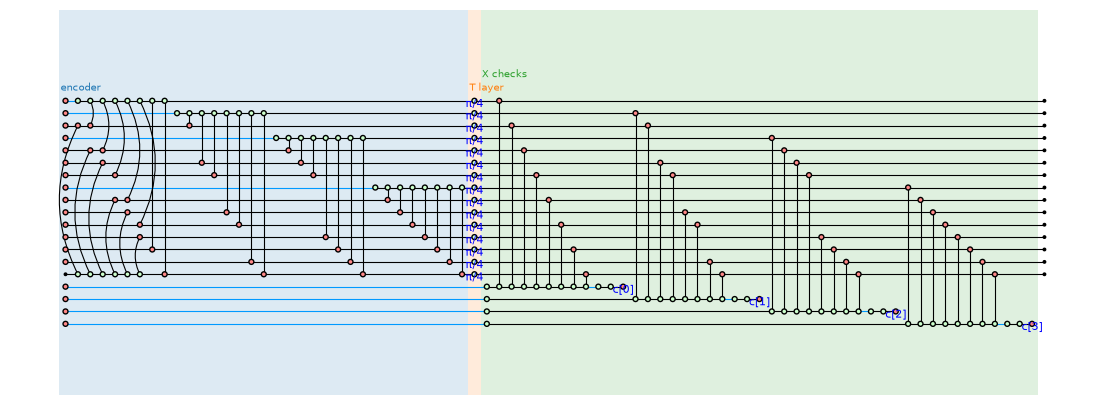

In [2]:
N = 19
HEAD = 'OPENQASM 2.0;\ninclude "qelib1.inc";\nqreg q[19];\ncreg c[4];\n'
ENCODER = "".join("cx q[14], q[{}];\n".format(j) for j in range(14) if bin(j + 1).count('1') % 2 == 0)
for b in range(4):
    pivot = (1 << b) - 1
    ENCODER += "h q[{}];\n".format(pivot) + "".join("cx q[{}], q[{}];\n".format(pivot, j) for j in range(15)
                                                    if (j + 1) >> b & 1 and j != pivot)
X_CHECKS = "".join("h q[{h}];\n".format(h=15 + b) + "".join("cx q[{}], q[{}];\n".format(15 + b, j) for j in range(15) if (j + 1) >> b & 1)
                   + "h q[{h}];\nmeasure q[{h}] -> c[{b}];\n".format(h=15 + b, b=b) for b in range(4))
STATES = {q: '0' for q in range(N) if q != 14}
BLOCKS = [(0, 0, 'encoder', 'encoder'), (1, 1, 'T layer', 'logical gate'), (2, 2, 'X checks', 'syndrome extraction')]

programs = {}
for name, qubits in (('T on all 15', range(15)), ('T on qubits 0-6', range(7))):
    p = QProgram(N, bits=4, initial_states=STATES)
    p.add_circuit(Circuit.from_qasm(HEAD + ENCODER), name='encoder')
    p.add_circuit(Circuit.from_qasm(HEAD + "".join("t q[{}];\n".format(j) for j in qubits)), name='T layer')
    p.add_circuit(Circuit.from_qasm(HEAD + X_CHECKS), name='X checks')
    programs[name] = p
references = {}
for gate in ('tdg', 't'):
    s = QProgram(N, bits=4, initial_states=STATES)
    s.add_circuit(Circuit.from_qasm(HEAD + "{} q[14];\n".format(gate)), name='logical gate')
    s.add_circuit(Circuit.from_qasm(HEAD + ENCODER), name='encoder')
    s.add_circuit(Circuit.from_qasm(HEAD + X_CHECKS), name='X checks')
    references[gate] = s
p = programs['T on all 15']
print(p.code_at(0).data())
draw_program(p, p.group_stages(BLOCKS), time_axis=False, show_time=False, even_rows=True, labels_above=True, figsize=(14, 5))

## 2. Code check: which code after the $T$ layer? (Question 1)

* **All 15.** The same code, [[15,1,3]]. The stored qubit now holds a non-Clifford state.
* **7 qubits.** A [[15,4,1]] code. Three checks no longer hold. Their rows count as stored qubits now. Distance 1: one error can change them unseen.

In [3]:
for name, p in programs.items():
    before, after = p.code_at(0), p.code_at(1)
    print("{}: after the encoder [[{}, {}, {}]], after the T layer [[{}, {}, {}]]; the same code: {}; non-Clifford: {}".format(
        name, *before.data().parameters, *after.data().parameters, after.same_code_as(before), after.non_clifford))

T on all 15: after the encoder [[15, 1, 3]], after the T layer [[15, 1, 3]]; the same code: True; non-Clifford: True


T on qubits 0-6: after the encoder [[15, 1, 3]], after the T layer [[15, 4, 1]]; the same code: False; non-Clifford: True


### How the tool sees it: the $T$ gadgets

**Picture 1.** Question 1 reduces "encoder, then $T$ layer". Each $T$ becomes a *phase gadget*: a $\pi/4$ that reads some of the encoder's green spiders. On the left: the logical spider (joined to the input) and the 4 check spiders. At the bottom right: the 15 gadgets.

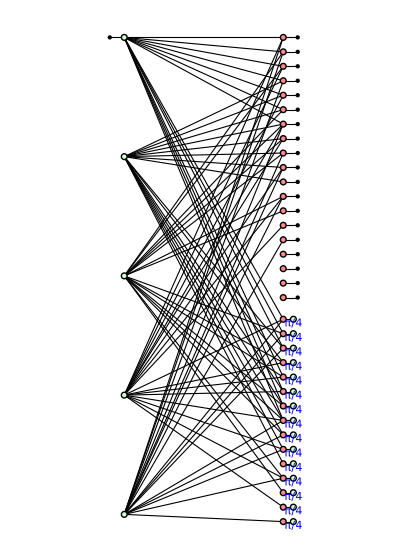

In [4]:
reduced = {name: reduce_gpf(p.prefix_graph(1), gadgets=False) for name, p in programs.items()}
zx.draw_matplotlib(reduced['T on all 15'].to_graph(), figsize=(5, 7))

**The matrix $M$.** One row per gadget. One column per green spider: first the logical spider, then the 4 check spiders. A 1 means: this gadget reads this spider.

In [5]:
columns = {}
for name, r in reduced.items():
    g = r.graph
    (logical,) = [u for b in g.inputs() for u in g.neighbors(b)]
    checks = sorted({w for hub, _leaves in phase_polynomial(g)[1] for w in g.neighbors(hub)
                     if g.type(w) == zx.VertexType.Z and w != logical and w not in _leaves})
    rows = [[int(s in g.neighbors(hub)) for s in [logical] + checks] for hub, _leaves in phase_polynomial(g)[1]]
    columns[name] = [[row[k] for row in rows] for k in range(1 + len(checks))]
    print("{}: {} gadgets; columns: logical, then {} checks".format(name, len(rows), len(checks)))
    for row in rows:
        print("   ", " ".join(map(str, row)))

T on all 15: 15 gadgets; columns: logical, then 4 checks
    1 0 0 1 1
    1 0 1 0 1
    1 1 0 0 1
    0 1 1 1 0
    1 0 1 1 0
    1 1 0 1 0
    1 1 1 0 0
    1 1 1 1 1
    0 1 1 0 1
    0 1 0 1 1
    0 1 0 0 0
    0 0 1 1 1
    0 0 1 0 0
    0 0 0 1 0
    0 0 0 0 1
T on qubits 0-6: 7 gadgets; columns: logical, then 3 checks
    1 0 1 1
    1 1 0 1
    0 1 1 1
    1 1 1 0
    0 1 0 0
    0 0 1 0
    0 0 0 1


**The three counts.** They ask, for the check columns:

* each column: its number of 1s is 0 mod 8;
* each pair of columns: the rows where both have a 1, 0 mod 4;
* each triple of columns: the rows where all three have a 1, 0 mod 2.

If these hold, the gadgets cancel on the checks (the spider-nest identity). The logical column is different: its count is what is *left*. Seven gadgets read the logical spider (the $T$ gates on the 7 qubits of the encoder's logical $X$), and $7 \cdot \pi/4 = 7\pi/4$, which is $T^\dagger$.

In [6]:
for name, cols in columns.items():
    names = ['logical'] + ['check spider {}'.format(k + 1) for k in range(len(cols) - 1)]
    print(name)
    print("  ones in each column (mod 8):", {n: sum(c) % 8 for n, c in zip(names, cols)})
    pairs = {(names[a], names[b]): sum(x * y for x, y in zip(cols[a], cols[b])) % 4 for a, b in combinations(range(len(cols)), 2)}
    print("  pair overlaps (mod 4), not zero:", {k: v for k, v in pairs.items() if v} or 'none')
    triples = {(names[a], names[b], names[c]): sum(x * y * z for x, y, z in zip(cols[a], cols[b], cols[c])) % 2
               for a, b, c in combinations(range(len(cols)), 3)}
    print("  triple overlaps (mod 2), not zero:", {k: v for k, v in triples.items() if v} or 'none')

T on all 15
  ones in each column (mod 8): {'logical': 7, 'check spider 1': 0, 'check spider 2': 0, 'check spider 3': 0, 'check spider 4': 0}
  pair overlaps (mod 4), not zero: none
  triple overlaps (mod 2), not zero: none
T on qubits 0-6
  ones in each column (mod 8): {'logical': 3, 'check spider 1': 4, 'check spider 2': 4, 'check spider 3': 4}
  pair overlaps (mod 4), not zero: {('logical', 'check spider 1'): 2, ('logical', 'check spider 2'): 2, ('logical', 'check spider 3'): 2, ('check spider 1', 'check spider 2'): 2, ('check spider 1', 'check spider 3'): 2, ('check spider 2', 'check spider 3'): 2}
  triple overlaps (mod 2), not zero: {('logical', 'check spider 1', 'check spider 2'): 1, ('logical', 'check spider 1', 'check spider 3'): 1, ('logical', 'check spider 2', 'check spider 3'): 1, ('check spider 1', 'check spider 2', 'check spider 3'): 1}


**What the tool does instead of checking the counts.** It adds all gadgets up into one polynomial (`phase_polynomial`). The numbers in the polynomial *are* these counts: one spider gets (its count) $\cdot\,\pi/4$, a pair gets (its overlap) $\cdot\,\pi/2$, a triple gets (its overlap) $\cdot\,\pi$. So a term on the checks is zero exactly when the three counts hold. What is left is the logical gate. No search for it is needed.

* **All 15.** One term is left: $7\pi/4$ on the logical bit. That is $T^\dagger$.
* **7 qubits.** 14 terms; 13 of them involve check bits. The gadgets do not cancel on the checks.

**Bravyi and Haah's "triorthogonal code"** asks the same counts modulo 2 only: pairs and triples even. Then the terms left on the checks are multiples of $\pi/2$ and $\pi$, so they are Clifford. The paper's Proposition proves how the three fit together: the three counts, Bravyi and Haah's counts, and the polynomial.

In [7]:
for name, r in reduced.items():
    poly, gadgets = phase_polynomial(r.graph)
    logical = {u for b in r.graph.inputs() for u in r.graph.neighbors(b)}
    print("{}: {} gadgets add up to {} term(s)".format(name, len(gadgets), len(poly)))
    for monomial, coefficient in poly.items():
        print("    {} pi x {}".format(coefficient, " * ".join('logical bit' if v[1] in logical else 'a check bit' for v in sorted(monomial, key=str))))

T on all 15: 15 gadgets add up to 1 term(s)
    7/4 pi x logical bit
T on qubits 0-6: 7 gadgets add up to 14 term(s)
    3/4 pi x logical bit
    1 pi x a check bit
    1 pi x a check bit
    1 pi x logical bit * a check bit
    1 pi x logical bit * a check bit
    1 pi x a check bit * a check bit
    1 pi x logical bit * a check bit * a check bit
    1 pi x a check bit
    1 pi x logical bit * a check bit
    1 pi x a check bit * a check bit
    1 pi x logical bit * a check bit * a check bit
    1 pi x a check bit * a check bit
    1 pi x a check bit * a check bit * a check bit
    1 pi x logical bit * a check bit * a check bit


**Picture 2.** After adding up, with $T$ on all 15: one gadget is left, $7\pi/4$ on the logical spider. The rest is the encoder, unchanged. So the code is the same, and the stored qubit carries $T^\dagger$.

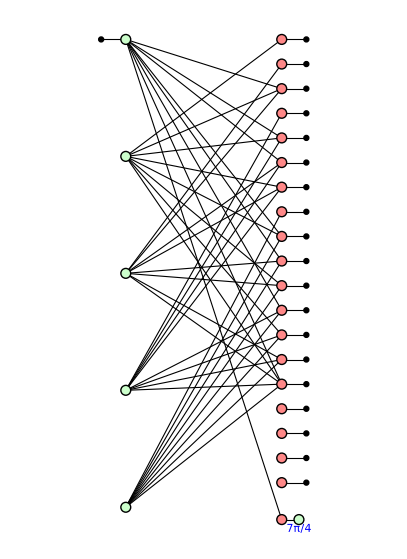

In [8]:
zx.draw_matplotlib(reduce_gpf(programs['T on all 15'].prefix_graph(1)).to_graph(), figsize=(5, 7))

## 3. Equivalence check: what does each block do? (Questions 2 and 3)

* **All 15.** The $T$ layer is $T^\dagger$ in every run. The checks do nothing to the stored qubit.
* **7 qubits.** The $T$ layer is flagged: it is not a logical gate. The checks are flagged too. But the whole program still gives $T^\dagger$: the checks put the state back into the code.

In [9]:
for name, p in programs.items():
    print(name); print(p.summary(p.group_stages(BLOCKS)).table()); print()
for name, p in programs.items():
    whole = p.level_up(p.group_stages(BLOCKS), 0, 2, name='whole program')
    print("{}, the whole program: {}".format(name, p.logical_action(whole, 0).verdict()))

T on all 15


block       role                 code before  code after  logical action  every run?  checks
0 encoder   encoder              [[1,1,1]]    [[15,1,3]]  I               yes         ok
1 T layer   logical gate         [[15,1,3]]   [[15,1,3]]  T^dag           yes         ok
2 X checks  syndrome extraction  [[15,1,3]]   [[15,1,3]]  I               yes         ok

T on qubits 0-6


block       role                 code before  code after  logical action  every run?  checks
0 encoder   encoder              [[1,1,1]]    [[15,1,3]]  I               yes         ok
1 T layer   logical gate         [[15,1,3]]   [[15,4,1]]  not recognised  yes         1 problem(s)
2 X checks  syndrome extraction  [[15,4,1]]   [[15,1,3]]  not recognised  no          3 problem(s)

T on all 15, the whole program: deterministic: every run implements T^dag


T on qubits 0-6, the whole program: deterministic: every run implements T^dag


## 4. Equivalence check: compare with the reference

`compare_programs` compares two programs. Same codes? Same logical action? Same checks (detectors)?

* **All 15 against "$T^\dagger$, then encode".** Logically equivalent. Both have 4 detectors.
* **All 15 against "$T$, then encode".** Not equivalent: $T^\dagger$ against $T$.
* **7 qubits against "$T^\dagger$, then encode".** Not equivalent. The logical action is the same, but only 1 detector instead of 4. Comparing logical maps alone would miss this.

In [10]:
for name, gate in (('T on all 15', 'tdg'), ('T on all 15', 't'), ('T on qubits 0-6', 'tdg')):
    print("--- {} against '{} q[14];' then the encoder".format(name, gate))
    print(compare_programs(programs[name], references[gate]))

--- T on all 15 against 'tdg q[14];' then the encoder


block          code before  code after  logical action  results checked
whole program  same         same        same
detectors: 4 and 4 independent, the same space
logically equivalent
--- T on all 15 against 't q[14];' then the encoder


block          code before  code after  logical action  results checked
whole program  same         same        DIFFERENT
detectors: 4 and 4 independent, the same space
NOT logically equivalent

whole programs  -- DIFFERENT
  code before     same
  code after      same
  logical action  DIFFERENT
  logical action: T^dag in the first, T in the second
--- T on qubits 0-6 against 'tdg q[14];' then the encoder


block          code before  code after  logical action  results checked
whole program  same         same        same
detectors: 1 and 4 independent, a different space
NOT logically equivalent


## 5. The checks after the $T$ layer (detectors)

A *detector* is a set of results whose sum is always 0. Stim cannot run this circuit (it has $T$ gates). The tool can.

* **All 15.** 4 detectors: together they say every check reads 0.
* **7 qubits.** 1 detector: only check 3 still reads 0. Check 3 acts on qubits 7–14, where there is no $T$. The other three checks can come out either way. An error that flips them is no longer seen.

In [11]:
for name, p in programs.items():
    report = p.measurement_report()
    print("{}: {} detector(s): {}".format(name, len(report.detectors), ", ".join("{} = 0".format(d) for d in report.detectors)))

T on all 15: 4 detector(s): c[2] + c[3] = 0, c[1] + c[3] = 0, c[0] + c[3] = 0, c[0] + c[1] + c[2] = 0


T on qubits 0-6: 1 detector(s): c[3] = 0


## 6. Distance check

* **Code distance** (Question 1): 3 for [[15,1,3]], 1 for [[15,4,1]].
* **Circuit distance**: the fewest faults anywhere in the circuit that change the stored qubit with every detector still 0.
* `circuit_distance` uses Stim. It refuses: $T$ is not a Clifford gate.
* `z_distance_through_t` works for $Z$ faults. A $Z$ fault passes through a $T$ unchanged. So it removes the $T$ gates, checks that the detectors stay the same, and asks Stim. Answer: 3.
* For the 7-qubit version it refuses: without the $T$ gates the detectors change.
* $X$ faults: an $X$ before a $T$ becomes a Clifford error, not a Pauli. The tool does not give the $X$ distance.

In [12]:
for name, p in programs.items():
    print("{}: the code after the T layer has distance {}".format(name, p.code_at(1).data().parameters[2]))
    try:
        circuit_distance(p, 1, 2, kind='Z')
    except Exception as e:
        print("   circuit_distance: {}: {}".format(type(e).__name__, e))
    try:
        print("   z_distance_through_t:", z_distance_through_t(p, 1, 2))
    except Exception as e:
        print("   z_distance_through_t: {}: {}".format(type(e).__name__, e))

T on all 15: the code after the T layer has distance 3


   circuit_distance: NotCliffordError: stage 1: T(0) is not a Clifford gate this function supports


   z_distance_through_t: Z circuit distance of stages 1-2: 3 (X -> X: 3, Z -> Z: None)


T on qubits 0-6: the code after the T layer has distance 1
   circuit_distance: NotCliffordError: stage 1: T(0) is not a Clifford gate this function supports


   z_distance_through_t: TRemovalError: the stages have 26 independent detectors with their T gates and 32 without them, 32 together (input logical X): removing the T gates changes what the detectors see


## 7. The levels window

Three levels, each rewritten by `'gpf'`: the encoder; the encoder and the $T$ layer (one gadget, $T^\dagger$); the whole program. Below: level 2, without the window's controls. [interactive_triorthogonal_levels.py](interactive_triorthogonal_levels.py) opens the window with them.

Level 1 (3 blocks), rewritten:
  Block 0: encoder (1 children): 90 spiders -> 24 after rewrite gpf
  Block 1: T layer (stage 1): 15 spiders -> 15 after no rewrite
  Block 2: X checks (stage 2): 80 spiders -> 80 after no rewrite
Level 2 (2 blocks), rewritten:
  Block 0: encoder + T layer (2 children): 39 spiders -> 26 after rewrite gpf
  Block 1: X checks (stage 2): 80 spiders -> 80 after no rewrite
Level 3 (1 blocks), rewritten:
  Block 0: whole program (2 children): 106 spiders -> 22 after rewrite gpf; 4 detector(s) removed here


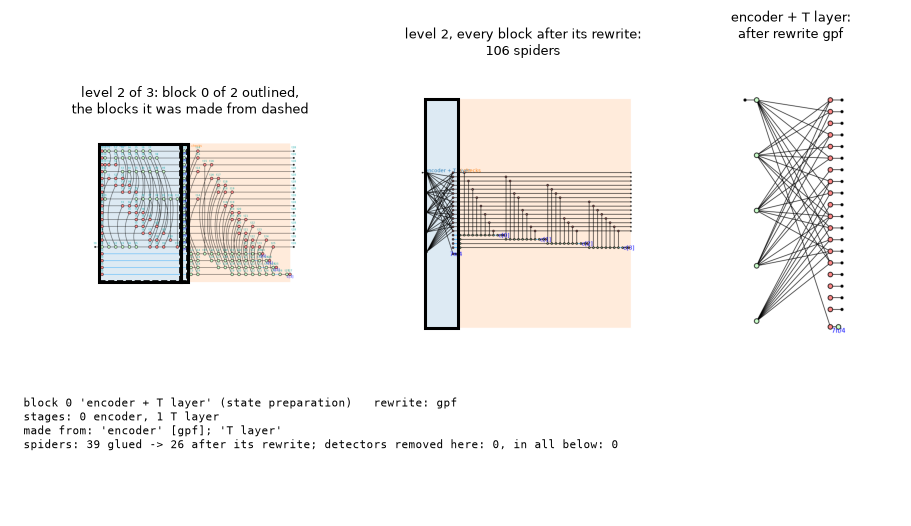

In [13]:
import interactive_triorthogonal_levels as window
r, levels = window.build(seven=False)
for level in levels:
    print(r.describe_reduced(level))
view = view_levels(r, levels[1], 0, controls=False, figsize=(9, 5.2), program_figsize=(12, 6),
                   level_figsize=(6, 6), block_figsize=(4, 6))
view

## In short

* From 15 $T$ gates and 4 measurements, the tool finds: the logical $T^\dagger$, the same code, 4 checks that read 0, and $Z$ distance 3.
* With $T$ on 7 qubits it finds what is lost: the code (for a moment), and 3 of the 4 checks.
* The matrix test checks the three counts on the matrix $M$. The tool adds the gadgets up. The same counts appear as the numbers of the polynomial, and the logical gate is what is left.